Name: Mia Parker

Github Username: emeliap-usc

ID: 1412-4907-44

In [154]:
import pandas as pd
import numpy as np
import os
import random
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score
import statsmodels.api as sm

In [ ]:
def list_files(base_path):
    """Return a list of (activity, file path) for every csv under base_path."""
    files = []
    for activity in os.listdir(base_path):
        activity_path = os.path.join(base_path, activity)
        if not os.path.isdir(activity_path):
            continue
        for data in os.listdir(activity_path):
            if data.endswith(".csv"):
                files.append((activity, os.path.join(activity_path, data)))
    return files


def read_series(data_path):
    """Read one file and return its 6 time series (time column dropped)."""
    columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

    with open(data_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                first_data_line = line.strip()
                break

    if "," in first_data_line:
        df = pd.read_csv(data_path, comment="#", names=columns, usecols=range(7))
    else:  # bending2 dataset4 is space separated
        df = pd.read_csv(data_path, comment="#", names=columns, sep=r"\s+")

    return df.drop(columns=["time"])


def build_features(base_path, l):
    rows = []
    activities = []

    for activity, data_path in list_files(base_path):
        df = read_series(data_path)
        row = {}

        for sensor, column in enumerate(df.columns, start=1):
            segments = np.array_split(df[column].to_numpy(), l)

            for seg, segment in enumerate(segments, start=1):
                row[f"median_{sensor}_{seg}"] = np.median(segment)
                row[f"q1_{sensor}_{seg}"] = np.quantile(segment, 0.25)
                row[f"q3_{sensor}_{seg}"] = np.quantile(segment, 0.75)

        rows.append(row)
        activities.append(activity)

    X = pd.DataFrame(rows)
    activity = pd.Series(activities, name="activity")
    y = activity.str.startswith("bending").astype(int).rename("label")
    return X, y, activity

# Part 2:

## a)

In [ ]:
start_path = "../data/HW3 Data Sorted/Training"

rows = []
for activity, data_path in list_files(start_path):
    df = read_series(data_path)
    row = {"activity": activity, "label": 1 if activity.startswith("bending") else 0}

    for count, column in enumerate(df.columns, start=1):
        row[f"median_{count}"] = df[column].median()
        row[f"q1_{count}"] = df[column].quantile(0.25)
        row[f"q3_{count}"] = df[column].quantile(0.75)

    rows.append(row)

features_df = pd.DataFrame(rows)

In [159]:
features_df

,activity,label,median_1,q1_1,q3_1,median_2,q1_2,q3_2,median_3,q1_3,q3_3,median_4,q1_4,q3_4,median_5,q1_5,q3_5,median_6,q1_6,q3_6
0,bending1,1,44.50,43.3100,44.67,0.47,0.430,0.5000,16.250,14.25,18.0000,0.470,0.000,0.9400,21.67,20.5000,23.7500,0.490,0.0000,0.8300
1,bending1,1,43.25,42.5000,45.00,0.47,0.000,0.5000,15.000,13.00,18.2700,0.500,0.430,1.1200,23.50,22.2500,24.0000,0.500,0.4300,0.8700
2,bending1,1,43.50,39.1500,45.00,0.50,0.000,1.1200,23.000,20.50,24.3725,0.830,0.430,1.3000,35.00,30.4575,36.3300,0.500,0.0000,1.0000
3,bending1,1,41.75,41.3300,42.75,0.50,0.430,0.7100,19.125,16.50,22.0625,0.500,0.430,1.1200,30.00,28.4575,31.2500,0.430,0.0000,0.5000
4,bending1,1,44.33,43.0000,45.00,0.47,0.000,0.5000,23.000,19.75,24.0000,0.430,0.000,0.8300,36.00,35.3625,36.5000,0.430,0.0000,0.9400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,cycling,0,36.00,33.0000,39.33,2.83,1.775,4.3300,16.000,13.73,18.3300,2.650,1.500,3.7800,16.25,14.0000,18.0625,2.770,1.7975,4.0600
65,cycling,0,36.25,34.5000,40.25,1.92,1.300,3.1300,16.670,14.25,19.0000,2.620,1.640,3.9175,20.00,17.9500,21.7500,2.500,1.5000,3.9000
66,cycling,0,36.75,33.4575,39.25,2.17,1.220,3.7400,18.330,15.67,21.0000,2.895,1.775,4.2400,18.50,15.7500,21.0000,3.110,2.1700,4.6175
67,cycling,0,36.29,34.5000,40.25,2.05,1.250,3.3500,15.250,13.25,17.3300,2.565,1.580,3.7700,16.33,14.0000,18.2500,2.525,1.6600,4.0300


In [160]:
selected_features = ["label",
    "q1_1", "median_1", "q3_1",
    "q1_2", "median_2", "q3_2",
    "q1_6", "median_6", "q3_6"
]

variables = features_df[selected_features]


In [161]:
variables

,label,q1_1,median_1,q3_1,q1_2,median_2,q3_2,q1_6,median_6,q3_6
0,1,43.3100,44.50,44.67,0.430,0.47,0.5000,0.0000,0.490,0.8300
1,1,42.5000,43.25,45.00,0.000,0.47,0.5000,0.4300,0.500,0.8700
2,1,39.1500,43.50,45.00,0.000,0.50,1.1200,0.0000,0.500,1.0000
3,1,41.3300,41.75,42.75,0.430,0.50,0.7100,0.0000,0.430,0.5000
4,1,43.0000,44.33,45.00,0.000,0.47,0.5000,0.0000,0.430,0.9400
...,...,...,...,...,...,...,...,...,...,...
64,0,33.0000,36.00,39.33,1.775,2.83,4.3300,1.7975,2.770,4.0600
65,0,34.5000,36.25,40.25,1.300,1.92,3.1300,1.5000,2.500,3.9000
66,0,33.4575,36.75,39.25,1.220,2.17,3.7400,2.1700,3.110,4.6175
67,0,34.5000,36.29,40.25,1.250,2.05,3.3500,1.6600,2.525,4.0300


### i

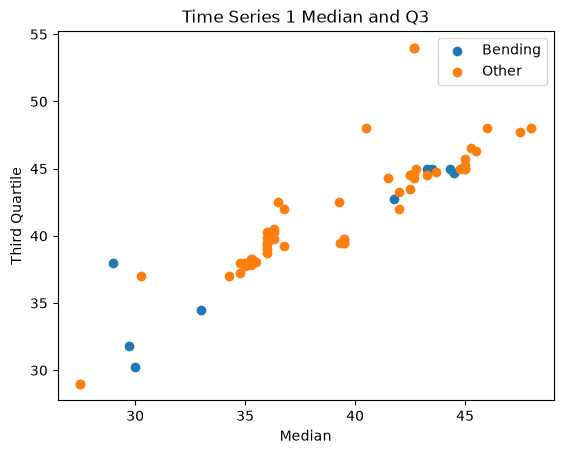

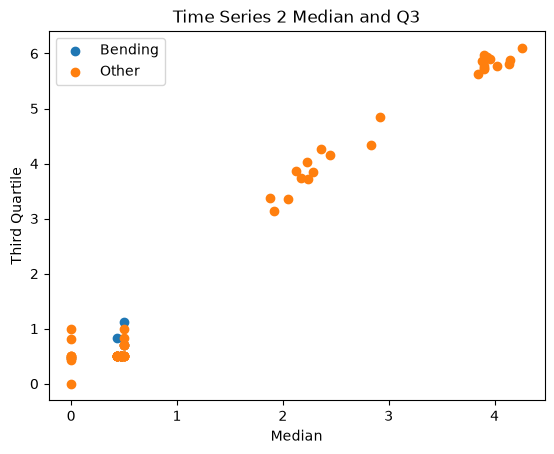

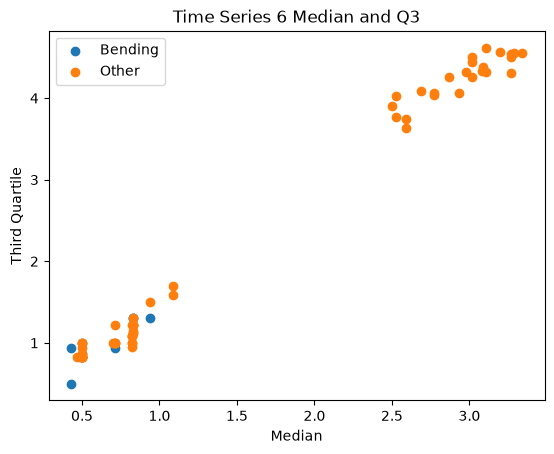

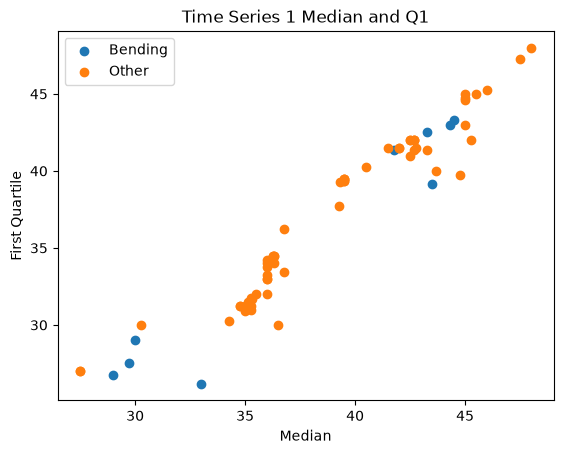

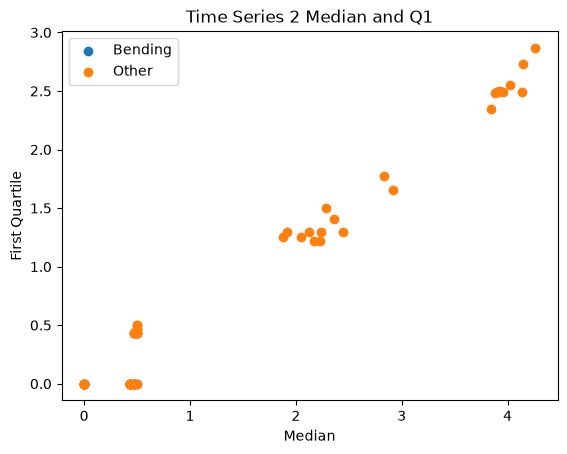

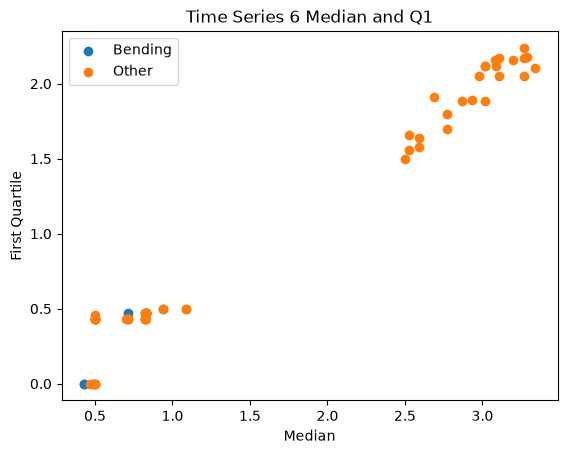

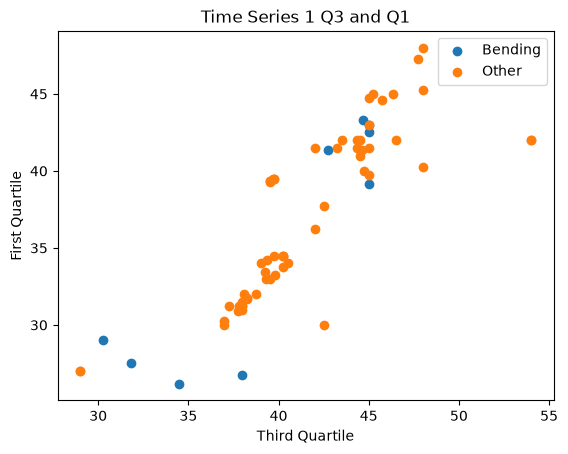

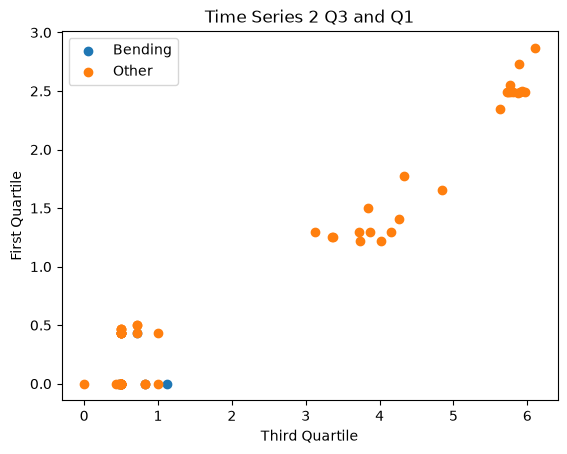

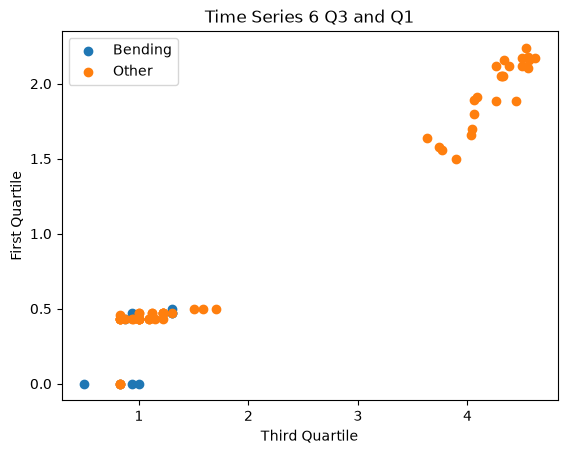

In [162]:
bending = features_df[features_df["label"] == 1]
other = features_df[features_df["label"] == 0]

for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}"], bending[f"q3_{i}"], label="Bending")
    plt.scatter(other[f"median_{i}"], other[f"q3_{i}"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("Third Quartile")
    plt.title(f"Time Series {i} Median and Q3")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}"], bending[f"q1_{i}"], label="Bending")
    plt.scatter(other[f"median_{i}"], other[f"q1_{i}"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Median and Q1")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"q3_{i}"], bending[f"q1_{i}"], label="Bending")
    plt.scatter(other[f"q3_{i}"], other[f"q1_{i}"], label="Other")

    plt.xlabel("Third Quartile")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Q3 and Q1")
    plt.legend()
    plt.show()

### ii

In [163]:
rows = []
for activity, data_path in list_files(start_path):
    df = read_series(data_path)
    row = {"activity": activity, "label": 1 if activity.startswith("bending") else 0}
    midpoint = len(df) // 2

    for count, column in enumerate(df.columns, start=1):
        halves = [("first", df[column].iloc[:midpoint]), ("second", df[column].iloc[midpoint:])]

        for part_name, part in halves:
            row[f"median_{count}_{part_name}"] = part.median()
            row[f"q1_{count}_{part_name}"] = part.quantile(0.25)
            row[f"q3_{count}_{part_name}"] = part.quantile(0.75)

    rows.append(row)

features_2aii = pd.DataFrame(rows)

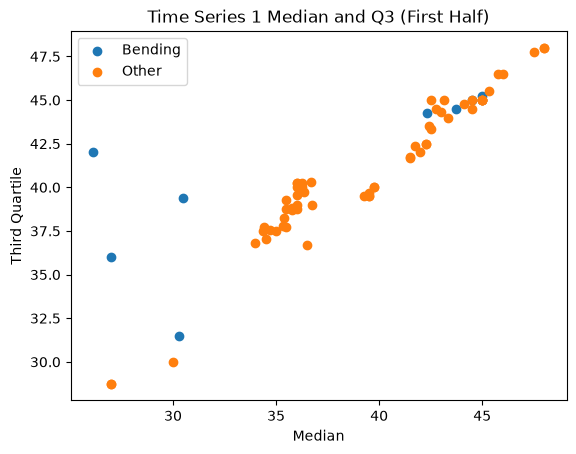

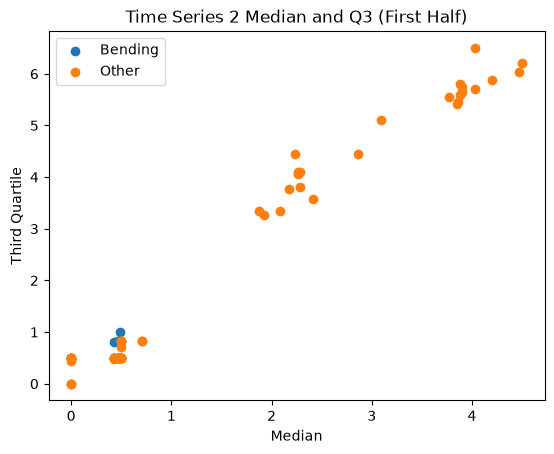

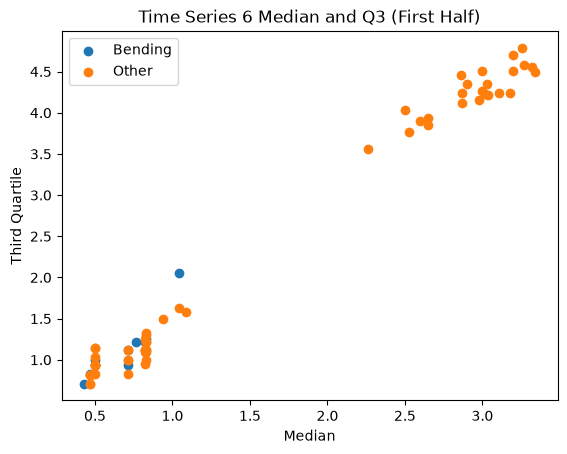

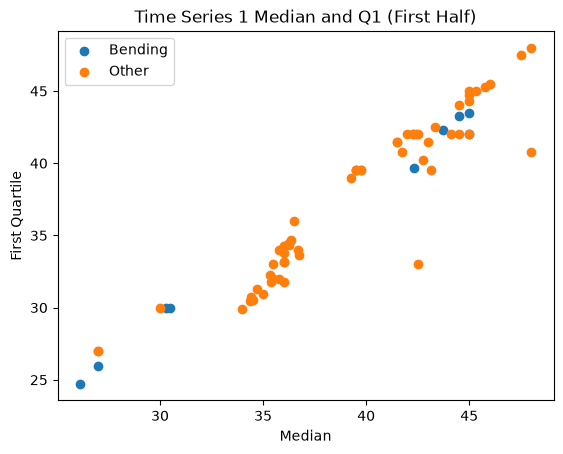

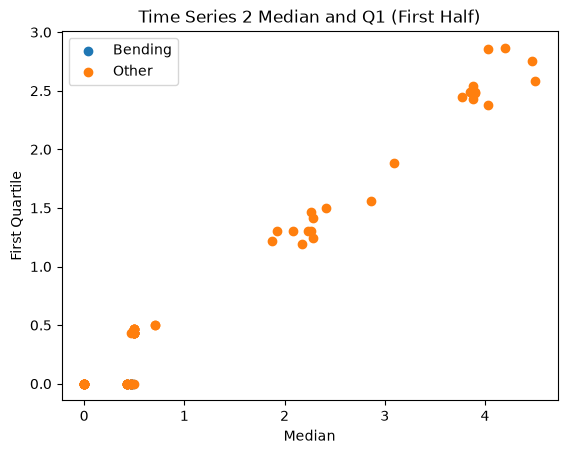

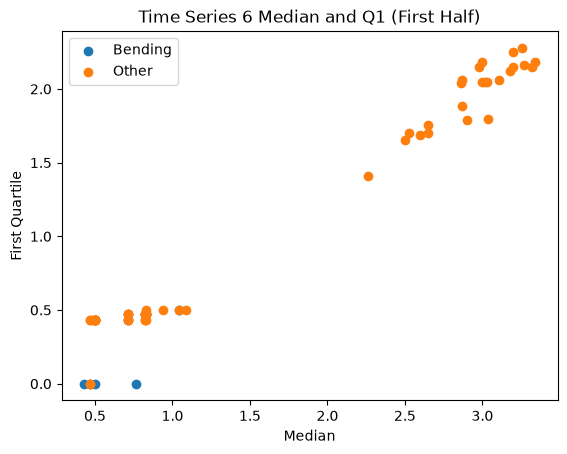

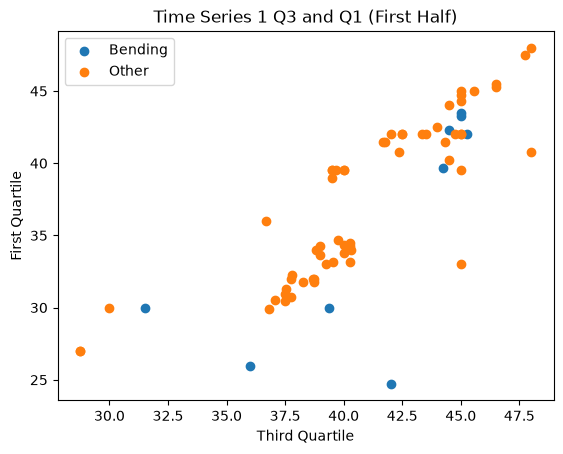

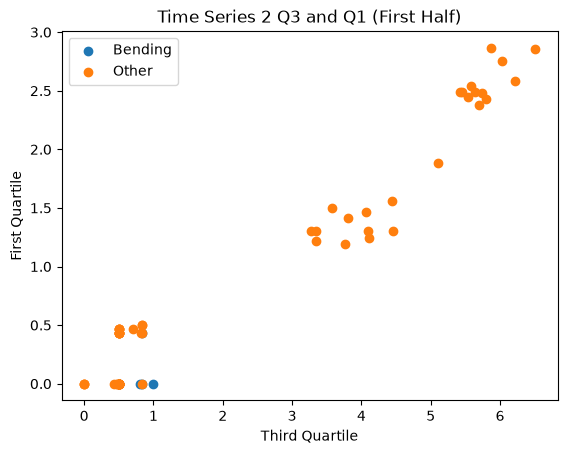

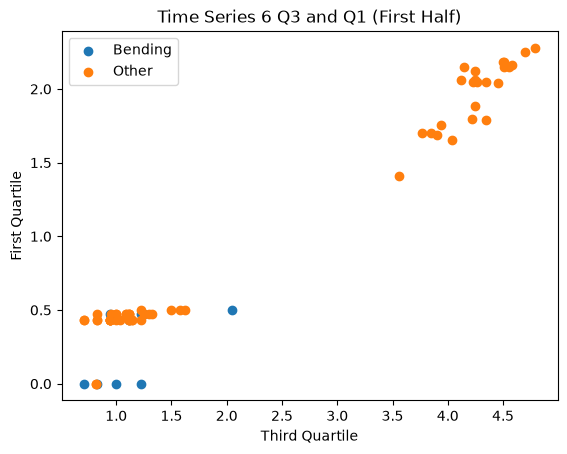

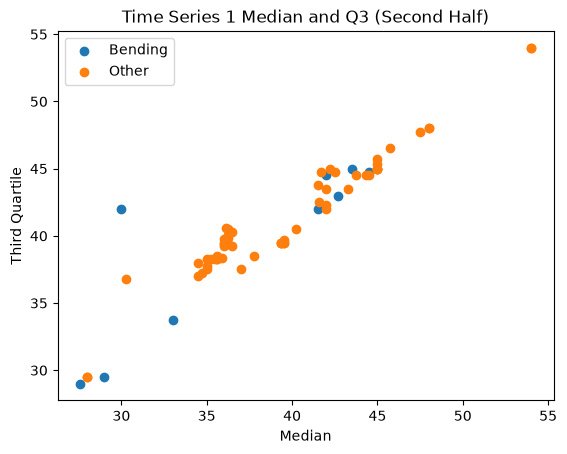

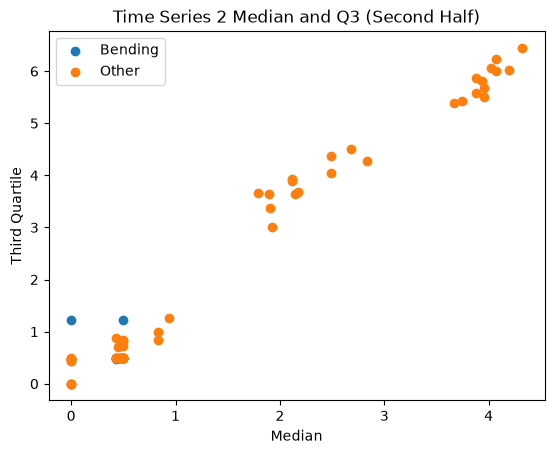

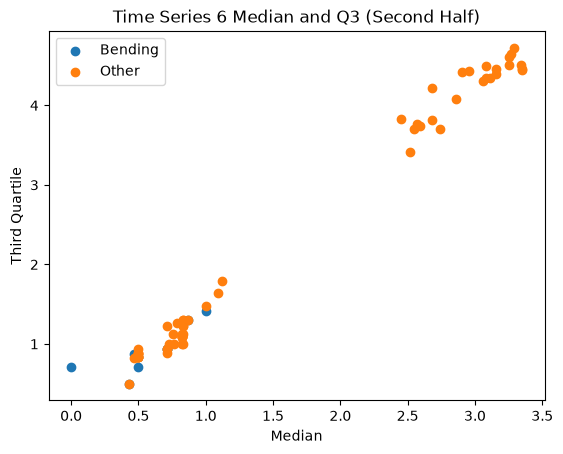

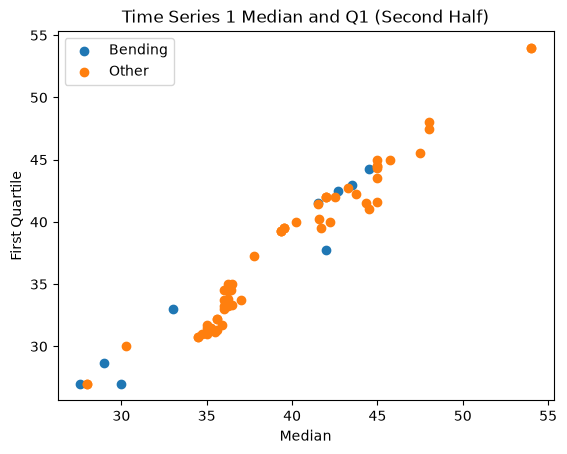

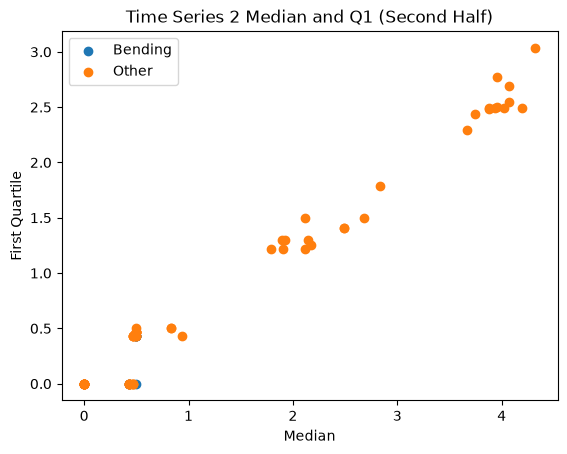

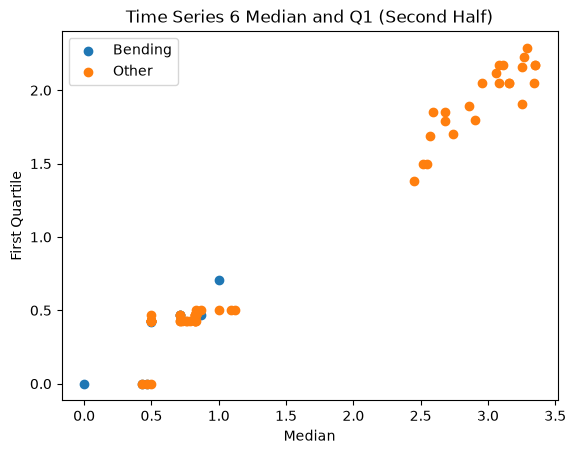

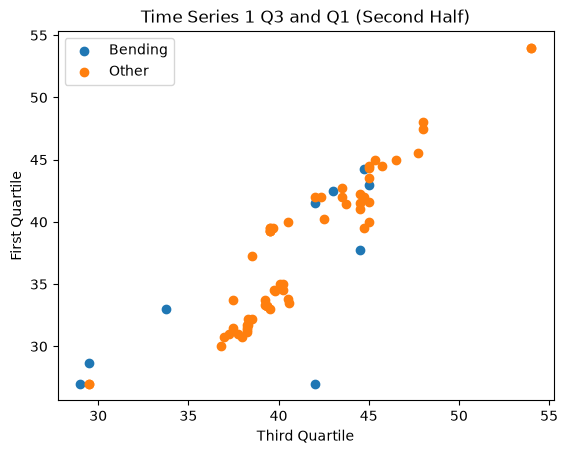

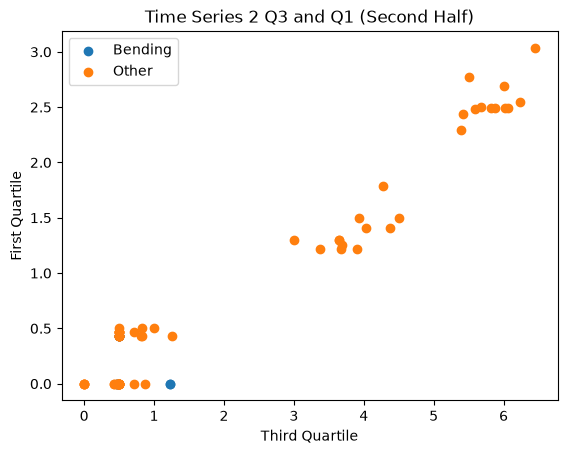

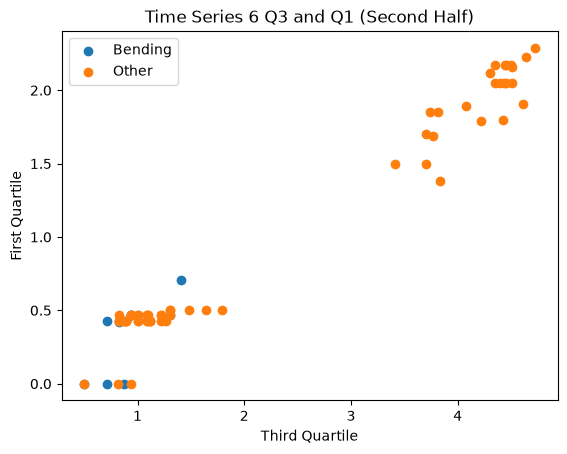

In [ ]:

bending = features_2aii[features_2aii["label"] == 1]
other = features_2aii[features_2aii["label"] == 0]


#First half of each time series
for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}_first"], bending[f"q3_{i}_first"], label="Bending")
    plt.scatter(other[f"median_{i}_first"], other[f"q3_{i}_first"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("Third Quartile")
    plt.title(f"Time Series {i} Median and Q3 (First Half)")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}_first"], bending[f"q1_{i}_first"], label="Bending")
    plt.scatter(other[f"median_{i}_first"], other[f"q1_{i}_first"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Median and Q1 (First Half)")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"q3_{i}_first"], bending[f"q1_{i}_first"], label="Bending")
    plt.scatter(other[f"q3_{i}_first"], other[f"q1_{i}_first"], label="Other")

    plt.xlabel("Third Quartile")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Q3 and Q1 (First Half)")
    plt.legend()
    plt.show()


#second half of each time series
for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}_second"], bending[f"q3_{i}_second"], label="Bending")
    plt.scatter(other[f"median_{i}_second"], other[f"q3_{i}_second"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("Third Quartile")
    plt.title(f"Time Series {i} Median and Q3 (Second Half)")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"median_{i}_second"], bending[f"q1_{i}_second"], label="Bending")
    plt.scatter(other[f"median_{i}_second"], other[f"q1_{i}_second"], label="Other")

    plt.xlabel("Median")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Median and Q1 (Second Half)")
    plt.legend()
    plt.show()

for i in [1, 2, 6]:
    plt.scatter(bending[f"q3_{i}_second"], bending[f"q1_{i}_second"], label="Bending")
    plt.scatter(other[f"q3_{i}_second"], other[f"q1_{i}_second"], label="Other")

    plt.xlabel("Third Quartile")
    plt.ylabel("First Quartile")
    plt.title(f"Time Series {i} Q3 and Q1 (Second Half)")
    plt.legend()
    plt.show()


After splitting each time series into two even sections and calculating each feature twice for each due to the splitting, I do not see a significant difference from the scatterplots made prior to splitting. There are two seperate groups that are generally created, sometimes 3 or a line of 1. The bending data is usually isolated to one group, but it is not seperate from the other. There are others in any of the three groups, and that is seen in the scatterplots from i and ii.

### iii

In [ ]:
results = []

for l in range(1, 21):

    X, y, _ = build_features(start_path, l)

    p_values = list(range(1, X.shape[1] + 1))

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=LogisticRegression(C=1e6, max_iter=1000),
            step=0.2
        )),
        ("logistic", LogisticRegression(C=1e6, max_iter=1000))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        model,
        param_grid={"rfe__n_features_to_select": p_values},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X, y)

    results.append({
        "l": l,
        "p": search.best_params_["rfe__n_features_to_select"],
        "accuracy": search.best_score_
    })

In [ ]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="accuracy",
    ascending=False
)

print(results_df)

best_result = results_df.iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_acc = best_result["accuracy"]

print(f"Best Result: l = {best_l}, p = {best_p}, accuracy = {best_acc:.4f}")


     l   p  accuracy
10  11   3  0.985714
8    9  79  0.985714
17  18  11  0.985714
14  15  32  0.985714
13  14   4  0.985714
11  12   7  0.985714
9   10  30  0.985714
19  20   3  0.985714
7    8  86  0.985714
6    7  68  0.985714
5    6   9  0.985714
4    5   7  0.985714
1    2   1  0.971429
12  13   5  0.971429
3    4  10  0.971429
15  16  39  0.971429
16  17   7  0.971429
2    3   1  0.971429
18  19   6  0.971429
0    1   4  0.942857
Best Result: l = 11, p = 3, accuracy = 0.9857


Wrong way: Select features (or scale) using the whole training set first, then cross-validate. The validation folds were already used to pick the features, so the accuracy looks better than it really is.

Right way: Redo the scaling and feature selection inside each fold, using only that fold's training data, then test on the held-out part. I did this by putting the scaler, RFE, and logistic regression in one Pipeline and passing it to GridSearchCV.

I used stratified 5-fold cross-validation because only 9 of the 69 training instances are bending, and stratifying keeps a similar share of bending in every fold.

### iv

### Reimporting data and calculating time series features for best l segments

In [168]:
X_train, y_train, _ = build_features(start_path, best_l)

print(X_train.shape)
print(y_train.value_counts())

(69, 198)
label
0    60
1     9
Name: count, dtype: int64


#### fitting the final model

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

rfe = RFE(estimator=LogisticRegression(C=1e6, max_iter=1000), n_features_to_select=best_p, step=0.2)
rfe.fit(X_train_scaled, y_train)

selected_cols = X_train.columns[rfe.support_]
print("Selected features:", list(selected_cols))

X_train_sel = X_train_scaled[:, rfe.support_]

clf = LogisticRegression(C=1e6, max_iter=1000)
clf.fit(X_train_sel, y_train)

Selected features: ['q1_3_8', 'median_5_2', 'q1_5_2']


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1000000.0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

#### Confusion Matrix and ROC and AUC Curve

Create Function for Confusion Matrix and ROC/AUC Curve because its done many times

In [170]:

def show_results(y_true, prob, title):

    pred = (prob >= 0.5).astype(int)
    print(f"{title} accuracy:", accuracy_score(y_true, pred))

    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=["Other", "Bending"]).plot()
    plt.title(f"Confusion Matrix ({title})")
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, prob)
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, prob):.4f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve ({title})")
    plt.legend()
    plt.show()

Train accuracy: 1.0


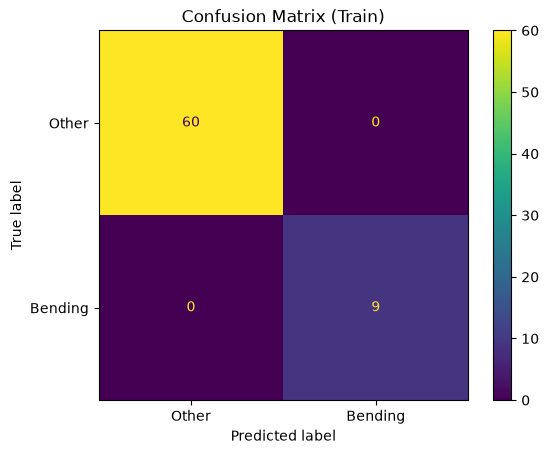

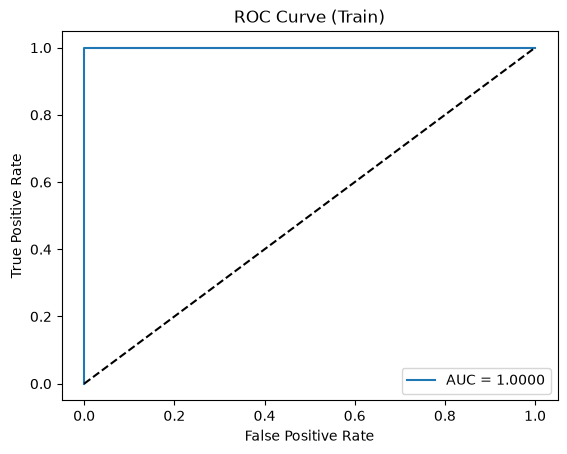

In [171]:
show_results(y_train, clf.predict_proba(X_train_sel)[:, 1], "Train")

In [ ]:
X_sm = sm.add_constant(pd.DataFrame(X_train_sel, columns=selected_cols))

try:
    logit_model = sm.Logit(y_train.reset_index(drop=True), X_sm).fit(method="bfgs", maxiter=1000)
    print(logit_model.summary())
except Exception as e:
    print("statsmodels failed:", e)

coef_table = pd.DataFrame({"feature": selected_cols, "beta": clf.coef_[0]})
print(coef_table)
print("Intercept:", clf.intercept_[0])

Optimization terminated successfully.
         Current function value: 0.000039
         Iterations: 35
         Function evaluations: 36
         Gradient evaluations: 36
                           Logit Regression Results                           
Dep. Variable:                  label   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.9999
Time:                        23:01:07   Log-Likelihood:             -0.0026849
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.485e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -121.2316   1337.312     -

### v

In [ ]:
test_path = "../data/HW3 Data Sorted/Testing"

X_test, y_test, _ = build_features(test_path, best_l)

print(X_test.shape)
print(y_test.value_counts())

(19, 198)
label
0    15
1     4
Name: count, dtype: int64


In [ ]:
X_test = X_test[X_train.columns]
X_test_scaled = scaler.transform(X_test)
X_test_sel = X_test_scaled[:, rfe.support_]

y_test_pred = clf.predict(X_test_sel)
y_test_prob = clf.predict_proba(X_test_sel)[:, 1]

print("Test accuracy:", accuracy_score(y_test, y_test_pred))

Test accuracy: 0.9473684210526315


The previous cross validation accuracy that we recieved on the training data was 1, which means it accuratky sorted the data into bending and other with no errors. When using this model on the test set, we recieved an accuracy of 0.947. While not fully accurate, it is still considered an accurate model and successful in its binary sorting.

Test accuracy: 0.9473684210526315


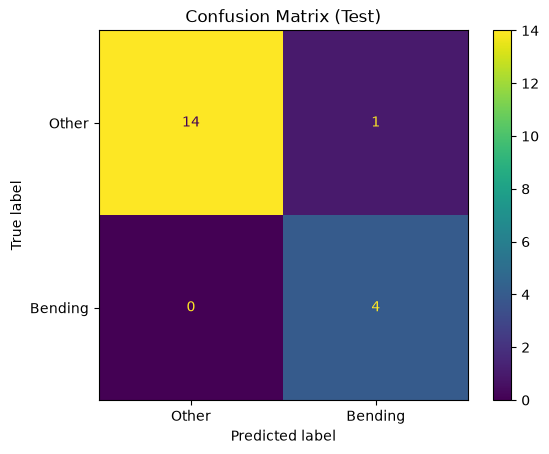

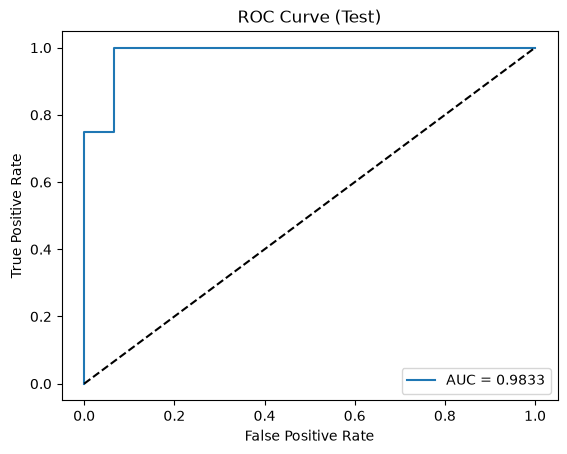

In [175]:
show_results(y_test, clf.predict_proba(X_test_sel)[:, 1], "Test") 

### vi-vii

vi: Yes, the classes are separable on training data. Because we were able to achieve 100% accuracy on our binary model with out training data, this must mean that our data is seperable. This is also reflected in the statsmodels output: the standard errors are extremely large and the p-values are near 1, which means the coefficient estimates are unstable and the p-values shouldn’t be interpreted.


vii: Yes, our data is imbalanced. We can easily see that because in our training set we have 60 datasets classified other versus 9 bending (about 13%), and in our testing data it is 15 versus 4. 

In [ ]:

rng = np.random.RandomState(42)

case_idx = np.where(y_train.to_numpy() == 1)[0]
control_idx = np.where(y_train.to_numpy() == 0)[0]

n_cases = len(case_idx)
N_controls = len(control_idx)

sampled_controls = rng.choice(control_idx, size=n_cases, replace=False)
cc_idx = np.concatenate([case_idx, sampled_controls])

X_cc = X_train_sel[cc_idx]
y_cc = y_train.to_numpy()[cc_idx]

clf_cc = LogisticRegression(C=1e6, max_iter=1000)
clf_cc.fit(X_cc, y_cc)

intercept_adj = clf_cc.intercept_[0] + np.log(n_cases / N_controls)

print("Intercept before adjustment:", clf_cc.intercept_[0])
print("Intercept after adjustment: ", intercept_adj)

coef_table_cc = pd.DataFrame({"feature": selected_cols, "beta": clf_cc.coef_[0]})
print(coef_table_cc)

Intercept before adjustment: -14.602824584042112
Intercept after adjustment:  -16.499944568927994
      feature       beta
0      q1_3_8   6.887482
1  median_5_2  11.273510
2      q1_5_2  20.802328


Train, Case-Control accuracy: 0.9855072463768116


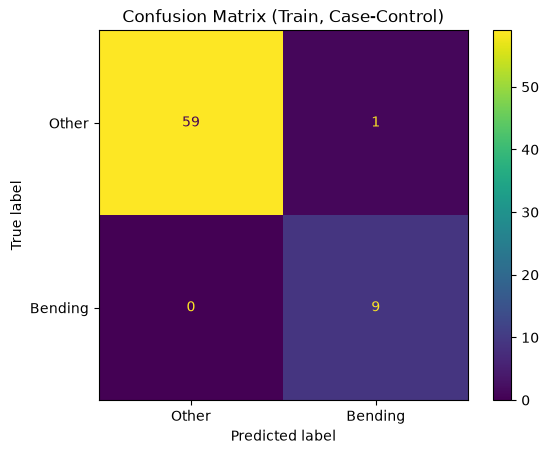

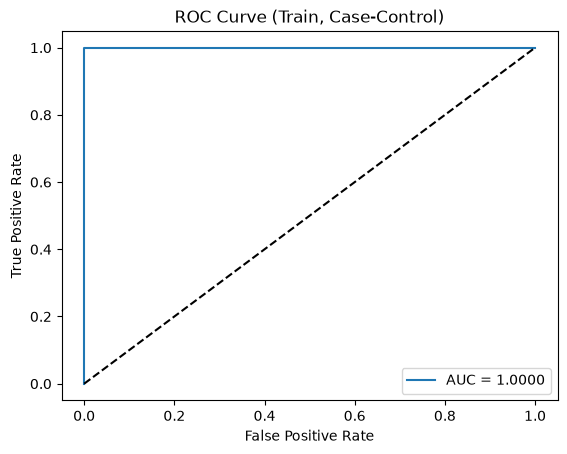

Test, Case-Control accuracy: 0.9473684210526315


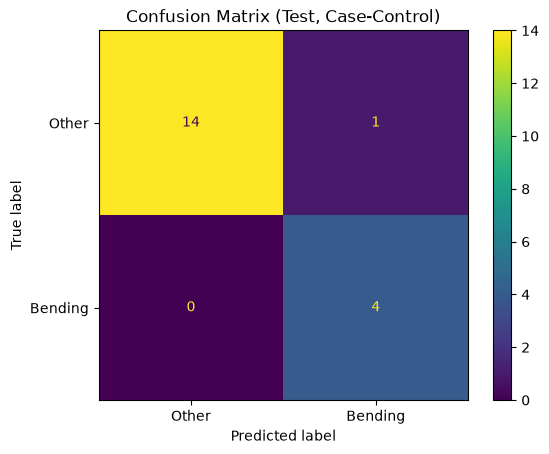

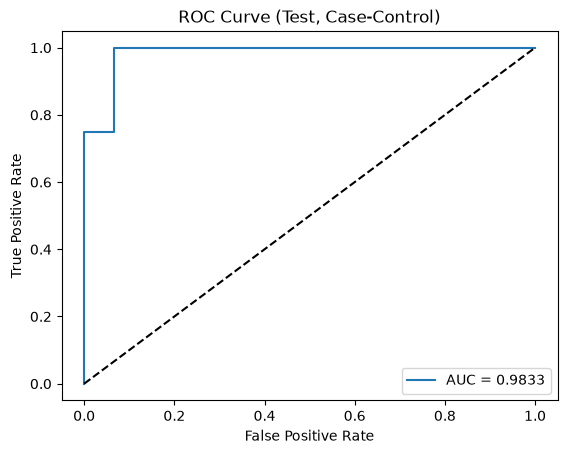

In [177]:
def predict_adjusted(X_sel):
    logit = X_sel @ clf_cc.coef_[0] + intercept_adj
    prob = 1 / (1 + np.exp(-logit))
    return prob, (prob >= 0.5).astype(int)

show_results(y_train, predict_adjusted(X_train_sel)[0], "Train, Case-Control")

show_results(y_test, predict_adjusted(X_test_sel)[0], "Test, Case-Control")

## b)

### i

In [ ]:
results_l1 = []

for l in range(1, 21):

    X, y, _ = build_features(start_path, l)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        model,
        param_grid={"logistic__C": np.logspace(-2, 2, 20)},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X, y)

    results_l1.append({
        "l": l,
        "C": search.best_params_["logistic__C"],
        "accuracy": search.best_score_
    })

In [ ]:
results_l1_df = pd.DataFrame(results_l1)

results_l1_df = results_l1_df.sort_values(
    by=["accuracy", "l"],
    ascending=[False, True]
)

print(results_l1_df)

best_result_l1 = results_l1_df.iloc[0]

best_l_l1 = int(best_result_l1["l"])
best_C_l1 = best_result_l1["C"]
best_acc_l1 = best_result_l1["accuracy"]

print(f"Best Result: l = {best_l_l1}, C = {best_C_l1:.4f}, accuracy = {best_acc_l1:.4f}")

     l           C  accuracy
4    5    2.069138  1.000000
5    6    2.069138  1.000000
11  12    3.359818  1.000000
18  19   23.357215  1.000000
19  20    2.069138  1.000000
7    8    8.858668  0.985714
10  11    3.359818  0.985714
12  13    3.359818  0.985714
14  15    2.069138  0.985714
15  16    1.274275  0.985714
17  18    0.784760  0.985714
3    4    5.455595  0.971429
8    9  100.000000  0.971429
16  17    1.274275  0.971429
2    3    8.858668  0.957143
0    1   37.926902  0.957143
6    7    0.483293  0.957143
9   10    3.359818  0.957143
13  14    0.784760  0.957143
1    2    0.784760  0.942857
Best Result: l = 5, C = 2.0691, accuracy = 1.0000


Train, L1 accuracy: 1.0


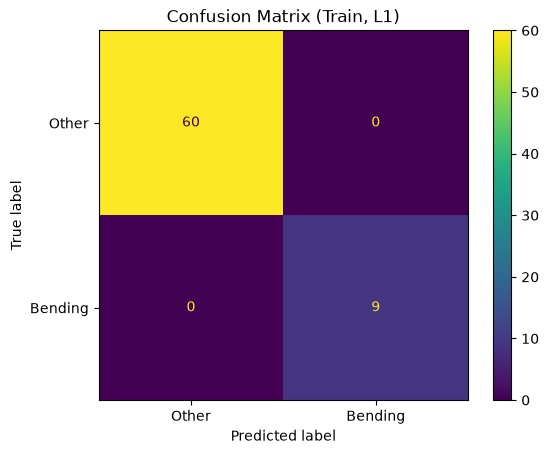

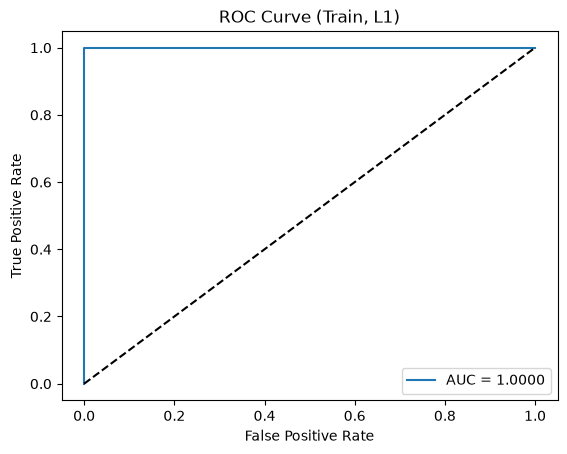

Test, L1 accuracy: 0.9473684210526315


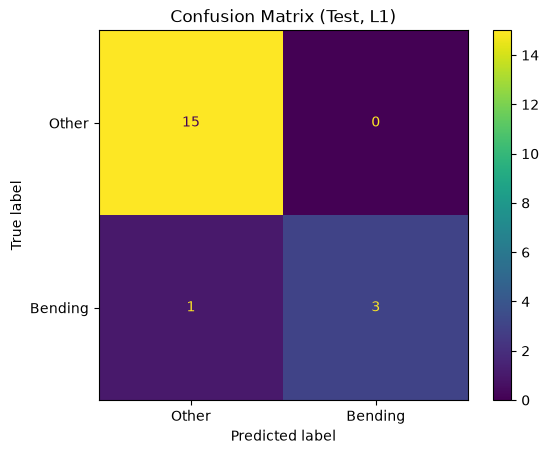

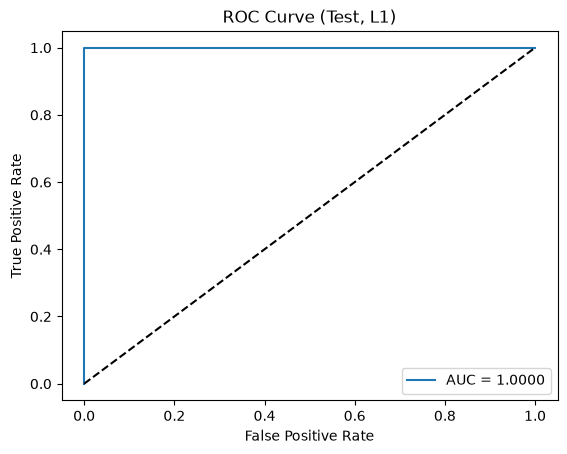

In [ ]:
X_train_l1, y_train_l1, _ = build_features(start_path, best_l_l1)
X_test_l1, y_test_l1, _ = build_features(test_path, best_l_l1)

X_test_l1 = X_test_l1[X_train_l1.columns]

scaler_l1 = StandardScaler()
X_train_l1_scaled = scaler_l1.fit_transform(X_train_l1)
X_test_l1_scaled = scaler_l1.transform(X_test_l1)

clf_l1 = LogisticRegression(l1_ratio=1, solver="liblinear", C=best_C_l1, max_iter=1000)
clf_l1.fit(X_train_l1_scaled, y_train_l1)

n_nonzero = int(np.sum(clf_l1.coef_[0] != 0))


show_results(y_train_l1, clf_l1.predict_proba(X_train_l1_scaled)[:, 1], "Train, L1")
show_results(y_test_l1, clf_l1.predict_proba(X_test_l1_scaled)[:, 1], "Test, L1")

### ii

Both methods performed the same: each achieved 100% cross-validation and training accuracy and 94.7% test accuracy. Due to this, we cannot conclude that one performed better, at least using accuracy as the determiner. The L_1-penalized approach was easier to implement because it performs variable selection automatically through regularization, whereas the p-value approach requires additional statistical testing and variable-selection decisions.

## c)

### i

In [181]:

feature_cache = {}

for l in range(1, 21):
    X, y_binary, activity = build_features(start_path, l)
    feature_cache[l] = (X, activity)

results_mn = []

for l in range(1, 21):

    X, activity = feature_cache[l]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=1, solver="saga", max_iter=5000))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        model,
        param_grid={"logistic__C": np.logspace(-1, 2, 8)},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X, activity)

    results_mn.append({
        "l": l,
        "C": search.best_params_["logistic__C"],
        "accuracy": search.best_score_
    })

results_mn_df = pd.DataFrame(results_mn).sort_values(by=["accuracy", "l"], ascending=[False, True])

best_result_mn = results_mn_df.iloc[0]
best_l_mn = int(best_result_mn["l"])
best_C_mn = best_result_mn["C"]

print(f"Best Result: l = {best_l_mn}, C = {best_C_mn:.4f}, accuracy = {best_result_mn['accuracy']:.4f}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/mode

Best Result: l = 1, C = 1.9307, accuracy = 0.9132


Train accuracy: 0.9855072463768116
Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474


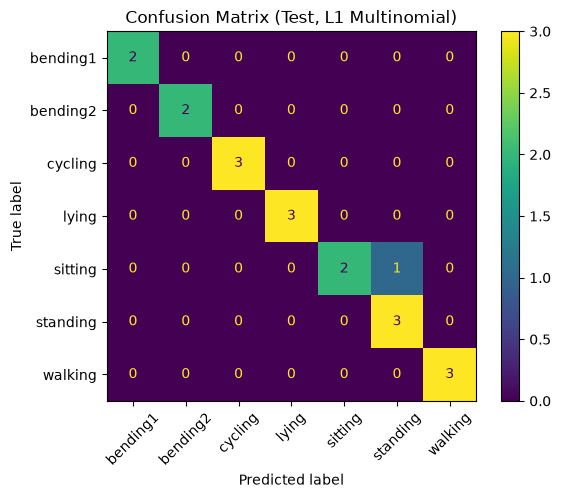

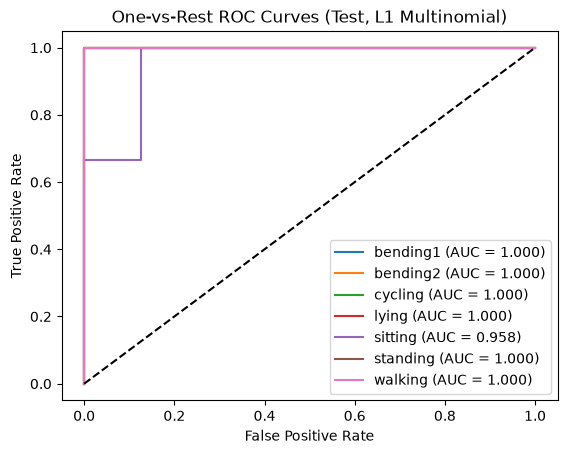

Macro-average AUC: 0.994047619047619


In [ ]:
X_train_mn, activity_train = feature_cache[best_l_mn]
X_test_mn, _, activity_test = build_features(test_path, best_l_mn)
X_test_mn = X_test_mn[X_train_mn.columns]

scaler_mn = StandardScaler()
X_train_mn_scaled = scaler_mn.fit_transform(X_train_mn)
X_test_mn_scaled = scaler_mn.transform(X_test_mn)

clf_mn = LogisticRegression(l1_ratio=1, solver="saga", C=best_C_mn, max_iter=5000)
clf_mn.fit(X_train_mn_scaled, activity_train)

classes = clf_mn.classes_

pred_mn = clf_mn.predict(X_test_mn_scaled)
prob_mn = clf_mn.predict_proba(X_test_mn_scaled)

print("Train accuracy:", accuracy_score(activity_train, clf_mn.predict(X_train_mn_scaled)))
print("Test accuracy:", accuracy_score(activity_test, pred_mn))
print("Test error:", 1 - accuracy_score(activity_test, pred_mn))

cm_mn = confusion_matrix(activity_test, pred_mn, labels=classes)
ConfusionMatrixDisplay(cm_mn, display_labels=classes).plot(xticks_rotation=45)
plt.title("Confusion Matrix (Test, L1 Multinomial)")
plt.show()

y_test_bin = label_binarize(activity_test, classes=classes)

for i, c in enumerate(classes):
    fpr_c, tpr_c, _ = roc_curve(y_test_bin[:, i], prob_mn[:, i])
    plt.plot(fpr_c, tpr_c, label=f"{c} (AUC = {roc_auc_score(y_test_bin[:, i], prob_mn[:, i]):.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves (Test, L1 Multinomial)")
plt.legend()
plt.show()

print("Macro-average AUC:", roc_auc_score(activity_test, prob_mn, multi_class="ovr", average="macro", labels=classes))

In [ ]:


results_nb = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for l in range(1, 21):

    X, activity = feature_cache[l]

    gnb_acc = cross_val_score(GaussianNB(), X, activity, cv=cv, scoring="accuracy").mean()
    mnb_acc = cross_val_score(MultinomialNB(), X, activity, cv=cv, scoring="accuracy").mean()

    results_nb.append({"l": l, "gaussian_acc": gnb_acc, "multinomial_acc": mnb_acc})

results_nb_df = pd.DataFrame(results_nb)

best_l_gnb = int(results_nb_df.sort_values(["gaussian_acc", "l"], ascending=[False, True]).iloc[0]["l"])
best_l_mnb = int(results_nb_df.sort_values(["multinomial_acc", "l"], ascending=[False, True]).iloc[0]["l"])

print("Best l for Gaussian NB:", best_l_gnb)
print("Best l for Multinomial NB:", best_l_mnb)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packa

Best l for Gaussian NB: 2
Best l for Multinomial NB: 2


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packa

Gaussian NB (l = 2)
  Test accuracy: 0.5789473684210527
  Test error: 0.42105263157894735
  Macro AUC: 0.8198529411764707


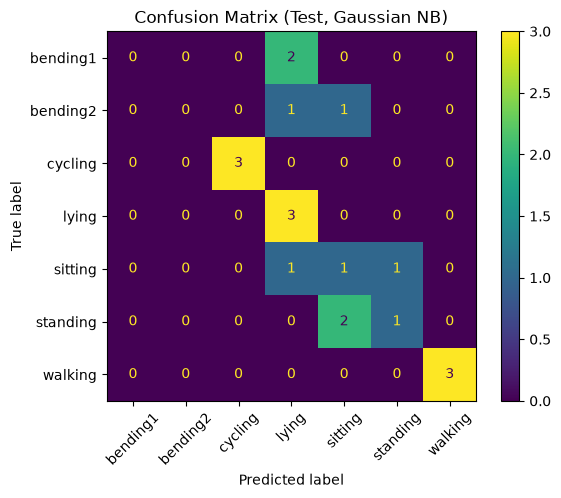

Multinomial NB (l = 2)
  Test accuracy: 0.7894736842105263
  Test error: 0.21052631578947367
  Macro AUC: 0.9851190476190476


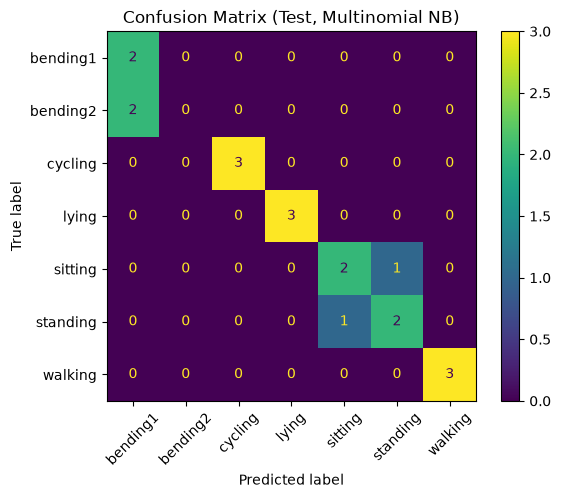

In [184]:
for name, model, l_nb in [("Gaussian NB", GaussianNB(), best_l_gnb),
                          ("Multinomial NB", MultinomialNB(), best_l_mnb)]:

    X_tr, act_tr = feature_cache[l_nb]
    X_te, _, act_te = build_features(test_path, l_nb)
    X_te = X_te[X_tr.columns]

    model.fit(X_tr, act_tr)
    pred_nb = model.predict(X_te)
    prob_nb = model.predict_proba(X_te)

    print(name, f"(l = {l_nb})")
    print("  Test accuracy:", accuracy_score(act_te, pred_nb))
    print("  Test error:", 1 - accuracy_score(act_te, pred_nb))
    print("  Macro AUC:", roc_auc_score(act_te, prob_nb, multi_class="ovr", average="macro", labels=model.classes_))

    ConfusionMatrixDisplay(
        confusion_matrix(act_te, pred_nb, labels=model.classes_),
        display_labels=model.classes_
    ).plot(xticks_rotation=45)
    plt.title(f"Confusion Matrix (Test, {name})")
    plt.show()

### iii

Regular: 0.9473684210526315

Guassian Naive: 0.5789473684210527

Multinomial Naive: 0.7894736842105263


Between the three multi-class methods that we used, the L1-penalized multinomial regression model performed the best by far, with an accuracy of 0.947. Our Gaussian Naive model performed the worst, with an accuracy of 0.579. Naïve Bayes assumes the features are independent, and medians and quartiles from the same segment are strongly correlated, which is a likely reason it does worse

# 4.8.3

This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class-specific mean vector and a class specific covariance matrix. We consider the simple case where p = 1; i.e. there is only one feature. Suppose that we have K classes, and that if an observation belongs to the kth class then X comes from a one-dimensional normal distribution, X∼ N (µk , σ2 k ). Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is not linear. Argue that it is in fact quadratic.
Hint: For this problem, you should follow the arguments laid out in Section 4.4.1, but without making the assumption that σ2 1 = . . . = σ2K.


***



If an observation is in class $k$, then $X \sim N(\mu_k, \sigma_k^2)$, with density from (4.16):

$$f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{1}{2\sigma_k^2}(x-\mu_k)^2\right)$$

The Bayes classifier assigns $x$ to the class with the largest $p_k(x)$, where

$$p_k(x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^{K}\pi_l f_l(x)}$$

(from 4.15 and 4.17).

The denominator is the same for every class, and the log is an increasing function. So we can instead pick the class with the largest $\log(\pi_k f_k(x))$:

$$\log\pi_k-\log\sqrt{2\pi}-\log\sigma_k-\frac{1}{2\sigma_k^2}(x-\mu_k)^2$$

The term $\log\sqrt{2\pi}$ is the same for all classes, so we drop it. Expanding the square, the Bayes classifier assigns $x$ to the class with the largest

$$\delta_k(x)=-\frac{1}{2\sigma_k^2}\,x^2+\frac{\mu_k}{\sigma_k^2}\,x-\frac{\mu_k^2}{2\sigma_k^2}+\log\pi_k-\log\sigma_k$$

Why this is not linear: In the LDA case (4.18), all classes share the same $\sigma^2$, so the $x^2$ term is identical for every class and cancels when classes are compared. That leaves a function that is linear in $x$.

Here, the coefficient of $x^2$ is $-\frac{1}{2\sigma_k^2}$, which is different for each class, so it does not cancel. Therefore $\delta_k(x)$ contains an $x^2$ term and is not linear.

Why it is quadratic: $\delta_k(x)$ is a polynomial in $x$ of degree 2 (an $x^2$ term, an $x$ term, and a constant). So the Bayes classifier is quadratic. This matches the QDA discriminant (4.28), where $x$ appears as a quadratic function.

# 4.8.7

Suppose that we wish to predict whether a given stock will issue a dividend this year (“Yes” or “No”) based on X, last year’s percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was ¯X = 10, while the mean for those that didn’t was ¯X = 0. In addition, the variance of X for these two sets of companies wasˆ σ2 = 36. Finally, 80 % of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X = 4 last year.
Hint: Recall that the density function for a normal random variable is f (x) = 1/√2πσ^2 e^(−(x−µ)^2 /2σ^2) . You will need to use Bayes’ theorem.

***

What we know:
- Dividend ("Yes"): $\mu_1 = 10$, prior $\pi_1 = 0.80$
- No dividend ("No"): $\mu_2 = 0$, prior $\pi_2 = 0.20$
- Common variance: $\sigma^2 = 36$, so $\sigma = 6$
- Last year's profit: $x = 4$


By Bayes' theorem (4.15) with normal densities (4.17),

$$P(\text{Yes}\mid X=4)=\frac{\pi_1 f_1(4)}{\pi_1 f_1(4)+\pi_2 f_2(4)}$$

where

$$f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma^2}\right)$$

Since both classes have the same $\sigma$, the factor $\frac{1}{\sqrt{2\pi}\,\sigma}$ is the same in the numerator and denominator and cancels. This leaves

$$P(\text{Yes}\mid X=4)=\frac{0.80\,\exp\left(-\frac{(4-10)^2}{2(36)}\right)}{0.80\,\exp\left(-\frac{(4-10)^2}{2(36)}\right)+0.20\,\exp\left(-\frac{(4-0)^2}{2(36)}\right)}$$

Compute the exponents

- Yes: $-\dfrac{(4-10)^2}{72}=-\dfrac{36}{72}=-0.5$, so $e^{-0.5}\approx 0.6065$
- No: $-\dfrac{(4-0)^2}{72}=-\dfrac{16}{72}\approx-0.2222$, so $e^{-0.2222}\approx 0.8007$


$$P(\text{Yes}\mid X=4)=\frac{0.80(0.6065)}{0.80(0.6065)+0.20(0.8007)}=\frac{0.4852}{0.4852+0.1601}=\frac{0.4852}{0.6454}\approx 0.752$$

Answer: The probability that the company issues a dividend, given a profit of 4% last year, is about **0.752 (75.2%)**.